# Task 3: Most common 311 complaint type in 2024

We use the CLI tool `borough_complaints.py` from Task 1 to get complaint counts, then plot them.

In [1]:
import subprocess
import io
import pandas as pd
import matplotlib.pyplot as plt

DATA = "data/311_2024.csv"

def complaint_counts(start, end):
    """Run borough_complaints.py for a date range and return a DataFrame."""
    out = subprocess.run(
        ["python3", "borough_complaints.py", "-i", DATA, "-s", start, "-e", end],
        capture_output=True, text=True, check=True).stdout
    return pd.read_csv(io.StringIO(out))

## Step 1: Find the overall most abundant complaint type (all of 2024)

In [2]:
year = complaint_counts("2024-01-01", "2024-12-31")
totals = year.groupby("complaint type")["count"].sum().sort_values(ascending=False)
top = totals.index[0]
print("Top 5 complaint types in 2024:")
print(totals.head())
print()
print("Most abundant complaint type:", top)

Top 5 complaint types in 2024:
complaint type
Illegal Parking            505546
Noise - Residential        379255
HEAT/HOT WATER             264715
Blocked Driveway           170140
Noise - Street/Sidewalk    162990
Name: count, dtype: int64

Most abundant complaint type: Illegal Parking


## Step 2: Counts for Jan-Feb and Jun-Jul 2024

In [3]:
jan_feb = complaint_counts("2024-01-01", "2024-02-29")
jun_jul = complaint_counts("2024-06-01", "2024-07-31")

jf = jan_feb[jan_feb["complaint type"] == top].set_index("borough")["count"]
jj = jun_jul[jun_jul["complaint type"] == top].set_index("borough")["count"]
print("Jan-Feb total:", jf.sum())
print("Jun-Jul total:", jj.sum())
print("Change: {:+.1f}%".format((jj.sum() - jf.sum()) / jf.sum() * 100))

Jan-Feb total: 79916
Jun-Jul total: 86237
Change: +7.9%


## Step 3: Bar chart for the first 2 months of 2024

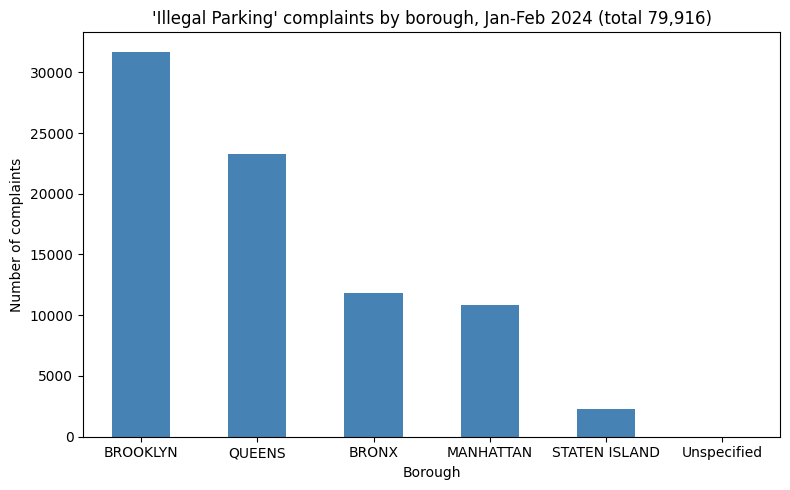

In [4]:
ax = jf.sort_values(ascending=False).plot(kind="bar", color="steelblue", figsize=(8, 5))
ax.set_title(f"'{top}' complaints by borough, Jan-Feb 2024 (total {jf.sum():,})")
ax.set_xlabel("Borough")
ax.set_ylabel("Number of complaints")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Step 4: Comparison with June-July 2024

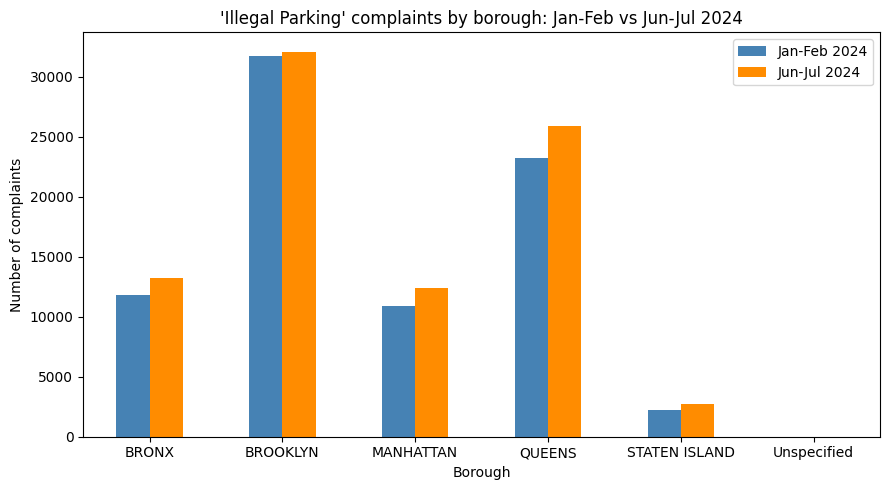

,Jan-Feb 2024,Jun-Jul 2024
borough,,
BRONX,11836,13189
BROOKLYN,31702,32077
MANHATTAN,10872,12366
QUEENS,23255,25861
STATEN ISLAND,2245,2734
Unspecified,6,10


In [5]:
cmp = pd.DataFrame({"Jan-Feb 2024": jf, "Jun-Jul 2024": jj}).fillna(0)
ax = cmp.plot(kind="bar", figsize=(9, 5), color=["steelblue", "darkorange"])
ax.set_title(f"'{top}' complaints by borough: Jan-Feb vs Jun-Jul 2024")
ax.set_xlabel("Borough")
ax.set_ylabel("Number of complaints")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
cmp